In [7]:
# Check R version
R.version.string

[1] "R version 4.6.1 (2026-06-24)"

In [8]:
install.packages(c(
  "dplyr",
  "ggplot2",
  "tidyr",
  "readr",
  "readxl",
  "writexl",
  "data.table"
))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [9]:
library(dplyr)
library(ggplot2)
library(tidyr)
library(readr)
library(readxl)
library(writexl)
library(data.table)

In [10]:
# Check R version
R.version.string

# Test calculation
a <- 10
b <- 20

a + b

[1] "R version 4.6.1 (2026-06-24)"

[1] 30

In [11]:
# Install packages for Social Network Analysis

install.packages(c(
  "igraph",
  "tidyverse"
))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [12]:
# Load required libraries

library(igraph)
library(tidyverse)


Attaching package: ‘igraph’


The following object is masked from ‘package:tidyr’:

    crossing


The following objects are masked from ‘package:dplyr’:

    as_data_frame, groups, union


The following objects are masked from ‘package:stats’:

    decompose, spectrum


The following object is masked from ‘package:base’:

    union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ lubridate 1.9.5     ✔ tibble    3.3.1
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ lubridate::%--%()       masks igraph::%--%()
✖ tibble::as_data_frame() masks igraph::as_data_frame(), dplyr::as_data_frame()
✖ data.table::between()   masks dplyr::between()
✖ purrr::compose()        masks igraph::compose()
✖ igraph::crossing()      masks tidyr::crossing()
✖ dplyr::filter()         masks stats::filter()
✖ data.table::first()     masks dplyr::first()
✖ lubridate::hour()       

In [13]:
# Create social network data
# Each row represents a relationship between two people

social_data <- data.frame(
  From = c(
    "Alice", "Alice", "Alice",
    "Bob", "Bob",
    "Charlie", "Charlie",
    "David", "David",
    "Eve", "Frank",
    "George"
  ),

  To = c(
    "Bob", "Charlie", "David",
    "Charlie", "Eve",
    "David", "Eve",
    "Eve", "Frank",
    "Frank", "George",
    "Alice"
  )
)

# Display the dataset
social_data

From,To
<chr>,<chr>
Alice,Bob
Alice,Charlie
Alice,David
Bob,Charlie
Bob,Eve
Charlie,David
Charlie,Eve
David,Eve
David,Frank


In [14]:
# Create an undirected social network

social_network <- graph_from_data_frame(
  social_data,
  directed = FALSE
)

# Display the network object
social_network


IGRAPH 7a833f7 UN-- 7 12 -- 
+ attr: name (v/c)
+ edges from 7a833f7 (vertex names):
 [1] Alice  --Bob     Alice  --Charlie Alice  --David   Bob    --Charlie
 [5] Bob    --Eve     Charlie--David   Charlie--Eve     David  --Eve    
 [9] David  --Frank   Eve    --Frank   Frank  --George  Alice  --George 

In [15]:
# Number of nodes
vcount(social_network)

# Number of edges
ecount(social_network)

[1] 7

[1] 12

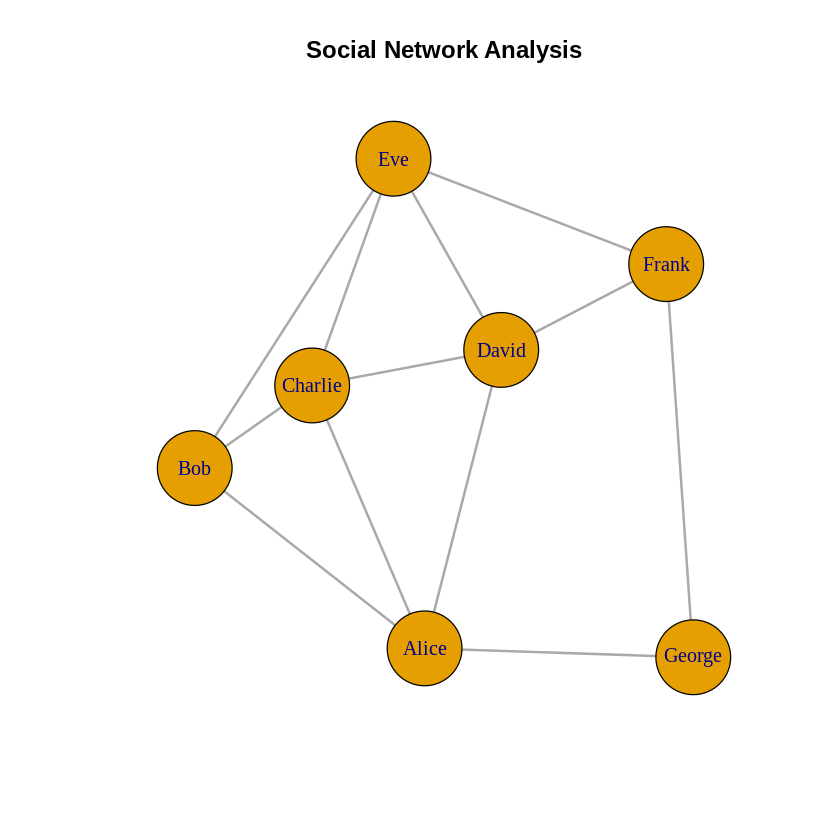

In [16]:
# Visualize the social network

plot(
  social_network,
  main = "Social Network Analysis",
  vertex.size = 30,
  vertex.label.cex = 1,
  edge.width = 2
)

In [17]:
# Calculate degree of each node

node_degree <- degree(social_network)

node_degree

Alice     Bob Charlie   David     Eve   Frank  George 
      4       3       4       4       4       3       2

In [18]:
# Display node names and their connections

degree_table <- data.frame(
  Person = names(node_degree),
  Connections = as.numeric(node_degree)
)

degree_table

Person,Connections
<chr>,<dbl>
Alice,4
Bob,3
Charlie,4
David,4
Eve,4
Frank,3
George,2


In [19]:
# Calculate centrality measures

degree_centrality <- degree(social_network)

betweenness_centrality <- betweenness(
  social_network,
  normalized = TRUE
)

closeness_centrality <- closeness(
  social_network,
  normalized = TRUE
)

# Create a centrality table

centrality_table <- data.frame(
  Person = V(social_network)$name,
  Degree = as.numeric(degree_centrality),
  Betweenness = as.numeric(betweenness_centrality),
  Closeness = as.numeric(closeness_centrality)
)

centrality_table

Person,Degree,Betweenness,Closeness
<chr>,<dbl>,<dbl>,<dbl>
Alice,4,0.18888889,0.7500000
Bob,3,0.02222222,0.6666667
Charlie,4,0.04444444,0.7500000
David,4,0.08888889,0.7500000
Eve,4,0.12222222,0.7500000
Frank,3,0.10000000,0.6666667
George,2,0.03333333,0.6000000


In [20]:
# Person with highest degree centrality

centrality_table %>%
  arrange(desc(Degree)) %>%
  slice(1)

Person,Degree,Betweenness,Closeness
<chr>,<dbl>,<dbl>,<dbl>
Alice,4,0.1888889,0.75


In [21]:
# Person with highest betweenness centrality

centrality_table %>%
  arrange(desc(Betweenness)) %>%
  slice(1)

Person,Degree,Betweenness,Closeness
<chr>,<dbl>,<dbl>,<dbl>
Alice,4,0.1888889,0.75


In [22]:
# Person with highest closeness centrality

centrality_table %>%
  arrange(desc(Closeness)) %>%
  slice(1)

Person,Degree,Betweenness,Closeness
<chr>,<dbl>,<dbl>,<dbl>
Alice,4,0.1888889,0.75


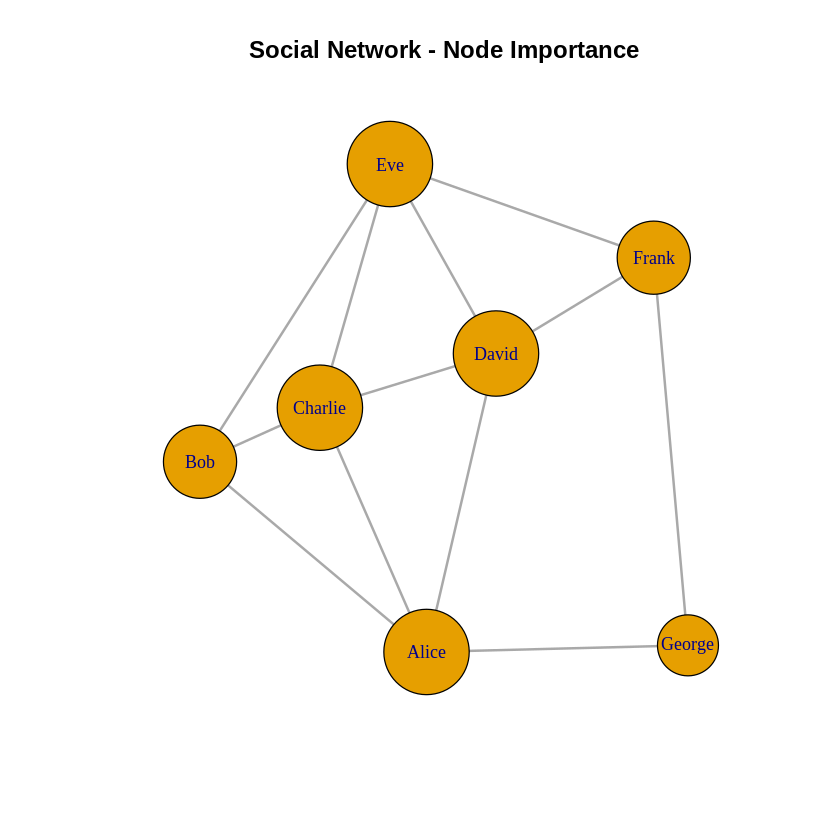

In [23]:
# Get degree of each node
node_degree <- degree(social_network)

# Scale node size based on number of connections
node_size <- 15 + (node_degree * 5)

# Create network visualization
plot(
  social_network,
  main = "Social Network - Node Importance",
  vertex.size = node_size,
  vertex.label = V(social_network)$name,
  vertex.label.cex = 0.9,
  edge.width = 2
)

In [24]:
# Identify the most connected person

most_connected <- centrality_table %>%
  arrange(desc(Degree)) %>%
  slice(1)

most_connected

Person,Degree,Betweenness,Closeness
<chr>,<dbl>,<dbl>,<dbl>
Alice,4,0.1888889,0.75


In [25]:
cat(
  "The most connected person is",
  most_connected$Person,
  "with",
  most_connected$Degree,
  "direct connections."
)

The most connected person is Alice with 4 direct connections.

In [26]:
# Identify the most influential bridge node

most_influential <- centrality_table %>%
  arrange(desc(Betweenness)) %>%
  slice(1)

most_influential

Person,Degree,Betweenness,Closeness
<chr>,<dbl>,<dbl>,<dbl>
Alice,4,0.1888889,0.75


In [27]:
cat(
  "The node with the highest betweenness centrality is",
  most_influential$Person,
  ". This person plays an important bridging role in the network."
)

The node with the highest betweenness centrality is Alice . This person plays an important bridging role in the network.

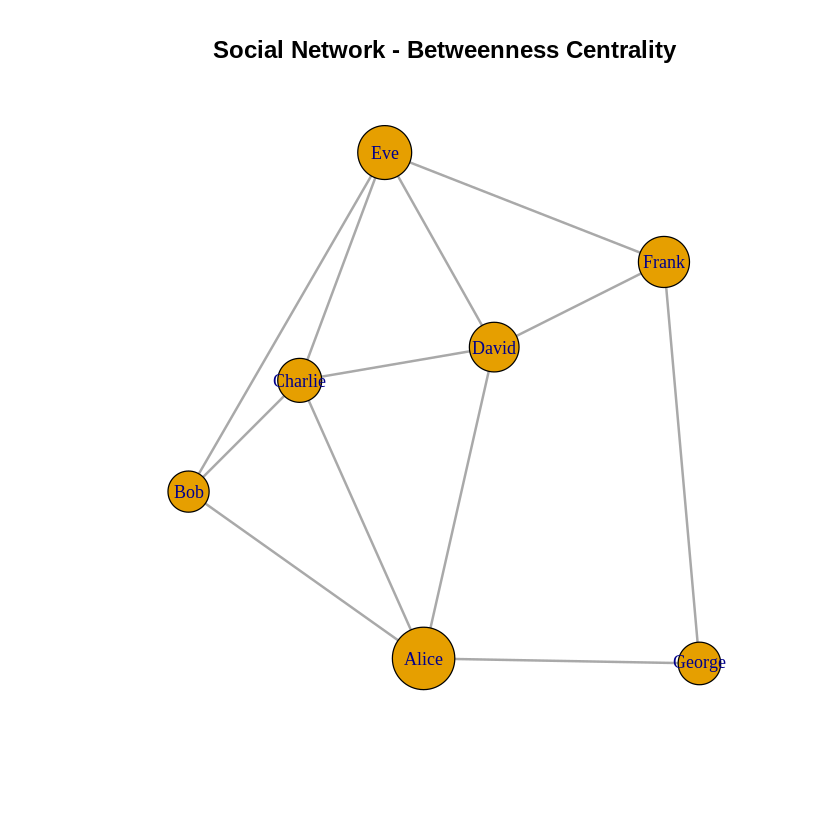

In [28]:
# Get betweenness centrality

node_betweenness <- betweenness(
  social_network,
  normalized = TRUE
)

# Scale node size
node_size_betweenness <- 15 + (node_betweenness * 50)

# Visualize network based on betweenness

plot(
  social_network,
  main = "Social Network - Betweenness Centrality",
  vertex.size = node_size_betweenness,
  vertex.label = V(social_network)$name,
  vertex.label.cex = 0.9,
  edge.width = 2
)

In [29]:
# Calculate overall network measures

network_density <- edge_density(social_network)

network_diameter <- diameter(social_network)

average_path_length <- mean_distance(
  social_network
)

average_degree <- mean(
  degree(social_network)
)

# Display results

cat("Network Measures\n")
cat("================\n")
cat("Number of Nodes:", vcount(social_network), "\n")
cat("Number of Edges:", ecount(social_network), "\n")
cat("Network Density:", round(network_density, 3), "\n")
cat("Network Diameter:", network_diameter, "\n")
cat("Average Path Length:", round(average_path_length, 3), "\n")
cat("Average Degree:", round(average_degree, 3), "\n")

Network Measures
Number of Nodes: 7 
Number of Edges: 12 
Network Density: 0.571 
Network Diameter: 2 
Average Path Length: 1.429 
Average Degree: 3.429 


In [30]:
# Final centrality results

centrality_table <- centrality_table %>%
  arrange(desc(Degree))

centrality_table

Person,Degree,Betweenness,Closeness
<chr>,<dbl>,<dbl>,<dbl>
Alice,4,0.18888889,0.7500000
Charlie,4,0.04444444,0.7500000
David,4,0.08888889,0.7500000
Eve,4,0.12222222,0.7500000
Bob,3,0.02222222,0.6666667
Frank,3,0.10000000,0.6666667
George,2,0.03333333,0.6000000


In [31]:
# Find important nodes

most_connected <- centrality_table %>%
  arrange(desc(Degree)) %>%
  slice(1)

most_influential <- centrality_table %>%
  arrange(desc(Betweenness)) %>%
  slice(1)

most_central <- centrality_table %>%
  arrange(desc(Closeness)) %>%
  slice(1)

# Display results

cat("FINAL NETWORK ANALYSIS RESULTS\n")
cat("==============================\n\n")

cat(
  "Most connected node:",
  most_connected$Person,
  "with",
  most_connected$Degree,
  "connections.\n"
)

cat(
  "Most influential bridge:",
  most_influential$Person,
  "with betweenness centrality of",
  round(most_influential$Betweenness, 3),
  ".\n"
)

cat(
  "Most central node by closeness:",
  most_central$Person,
  "with closeness centrality of",
  round(most_central$Closeness, 3),
  ".\n"
)

cat(
  "\nNetwork density:",
  round(network_density, 3),
  "\n"
)

cat(
  "Network diameter:",
  network_diameter,
  "\n"
)

cat(
  "Average path length:",
  round(average_path_length, 3),
  "\n"
)

FINAL NETWORK ANALYSIS RESULTS

Most connected node: Alice with 4 connections.
Most influential bridge: Alice with betweenness centrality of 0.189 .
Most central node by closeness: Alice with closeness centrality of 0.75 .

Network density: 0.571 
Network diameter: 2 
Average path length: 1.429 


In [32]:
cat("INTERPRETATION\n")
cat("==============\n\n")

cat(
  "1. The social network contains",
  vcount(social_network),
  "nodes and",
  ecount(social_network),
  "relationships. This represents the entities and connections present in the prepared dataset.\n\n"
)

cat(
  "2. ",
  most_connected$Person,
  "is the most highly connected node, having",
  most_connected$Degree,
  "direct connections. This indicates a relatively strong direct presence in the network.\n\n"
)

cat(
  "3. ",
  most_influential$Person,
  "has the highest betweenness centrality. This suggests that the node can play an important bridging role between other nodes in the network.\n\n"
)

cat(
  "4. The network density is",
  round(network_density, 3),
  ", indicating the proportion of possible connections that actually exist in the network.\n\n"
)

cat(
  "5. The network diameter is",
  network_diameter,
  "and the average path length is",
  round(average_path_length, 3),
  ". These measures describe how many steps are required to connect nodes across the network.\n"
)

INTERPRETATION

1. The social network contains 7 nodes and 12 relationships. This represents the entities and connections present in the prepared dataset.

2.  Alice is the most highly connected node, having 4 direct connections. This indicates a relatively strong direct presence in the network.

3.  Alice has the highest betweenness centrality. This suggests that the node can play an important bridging role between other nodes in the network.

4. The network density is 0.571 , indicating the proportion of possible connections that actually exist in the network.

5. The network diameter is 2 and the average path length is 1.429 . These measures describe how many steps are required to connect nodes across the network.


In [33]:
cat("========== FINAL VERIFICATION ==========\n\n")

cat("Nodes:", vcount(social_network), "\n")
cat("Edges:", ecount(social_network), "\n")
cat("Density:", round(network_density, 3), "\n")
cat("Diameter:", network_diameter, "\n")
cat("Average Path Length:", round(average_path_length, 3), "\n\n")

cat("Centrality Results:\n")
print(centrality_table)

cat("\nAll required analysis completed successfully.\n")

========== FINAL VERIFICATION ==========

Nodes: 7 
Edges: 12 
Density: 0.571 
Diameter: 2 
Average Path Length: 1.429 

Centrality Results:
   Person Degree Betweenness Closeness
1   Alice      4  0.18888889 0.7500000
2 Charlie      4  0.04444444 0.7500000
3   David      4  0.08888889 0.7500000
4     Eve      4  0.12222222 0.7500000
5     Bob      3  0.02222222 0.6666667
6   Frank      3  0.10000000 0.6666667
7  George      2  0.03333333 0.6000000

All required analysis completed successfully.
